In [1]:
import os
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import textwrap

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

In [2]:
csv_files = glob.glob('strategy_one_swapped_results/results_*.csv')

df_list = [pd.read_csv(file) for file in csv_files]
df = pd.concat(df_list, ignore_index=True)

print(f"Combined dataframe shape: {df.shape}")

df.columns

Combined dataframe shape: (216, 13)


Index(['id', 'timestamp', 'model', 'pair', 'option_1', 'option_2',
       'selected_choice', 'response_text', 'infection_rate_selected',
       'npi_level_selected', 'infection_rate_non_selected',
       'npi_level_non_selected', 'temperature'],
      dtype='object')

In [3]:
# Create is_bad_choice column
# A bad choice is either:
# 1. Selecting higher infection rate with same or stricter NPI
# 2. Selecting stricter NPI with same or lower infection rate
df['is_bad_choice'] = (
    ((df['infection_rate_selected'] > df['infection_rate_non_selected']) & 
     (df['npi_level_selected'] >= df['npi_level_non_selected'])) |
    ((df['npi_level_selected'] > df['npi_level_non_selected']) & 
    (df['infection_rate_selected'] <= df['infection_rate_non_selected']))
)

df['is_bad_choice'].value_counts()

is_bad_choice
True     115
False    101
Name: count, dtype: int64

In [4]:
# Extract second letter from pair column (e.g., "A-B" -> "B")
df['second_option_letter'] = df['pair'].str.split('-').str[1]

# Check if selected choice matches second option
df['is_second_choice'] = df['selected_choice'] == df['second_option_letter']

# Check the distribution
print(df['is_second_choice'].value_counts())
print(f"\nPercentage selecting second option: {df['is_second_choice'].mean() * 100:.2f}%")

is_second_choice
True     115
False    101
Name: count, dtype: int64

Percentage selecting second option: 53.24%


In [5]:
df['infection_preference'] = (df['infection_rate_selected'] - df['infection_rate_non_selected'])
df['npi_preference'] = (df['npi_level_selected'] - df['npi_level_non_selected'])

In [6]:
def generate_errorbar_plot(response_col, df, context_cols=None, use_percentage=False):
    import textwrap
    from scipy import stats
    
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    sns.set_theme(style='whitegrid')
    
    # Configuration
    MAX_LABEL_LENGTH = 30  # Characters per line
    if context_cols is None:
        context_cols = ['model']
    
    # Set unit label based on percentage flag
    unit = '%' if use_percentage else ''
    
    # Calculate overall mean for reference line
    overall_mean = df[response_col].mean()
    if use_percentage:
        overall_mean = overall_mean * 100
    
    # Wrap labels to multiple lines
    def wrap_label(text, max_len=MAX_LABEL_LENGTH):
        """Wrap text to multiple lines"""
        text = str(text)
        return '\n'.join(textwrap.wrap(text, width=max_len))
    
    # Create separate plot for each context
    for col in context_cols:
        grouped = df.groupby(col)[response_col]
        
        # Calculate means and 95% CI for each group
        means = []
        ci_lower = []
        ci_upper = []
        labels = []
        group_names = []
        
        for name, group in grouped:
            if len(group) > 0:
                # Get data
                data = group.values
                if use_percentage:
                    data = data * 100
                
                # Calculate mean
                mean_val = data.mean()
                means.append(mean_val)
                group_names.append(name)
                
                # Calculate 95% CI using scipy
                ci = stats.t.interval(0.95, len(data)-1, 
                                     loc=mean_val, 
                                     scale=stats.sem(data))
                ci_lower.append(mean_val - ci[0])
                ci_upper.append(ci[1] - mean_val)
                labels.append(wrap_label(str(name)))
        
        # Sort by mean values (descending)
        sorted_indices = sorted(range(len(means)), key=lambda i: means[i], reverse=True)
        means = [means[i] for i in sorted_indices]
        ci_lower = [ci_lower[i] for i in sorted_indices]
        ci_upper = [ci_upper[i] for i in sorted_indices]
        labels = [labels[i] for i in sorted_indices]
        
        # Adjust figure height based on number of items
        fig_height = max(6, len(labels) * 0.6)
        fig, ax = plt.subplots(figsize=(12, fig_height))
        
        # Create horizontal error bar plot
        y_positions = range(1, len(labels) + 1)
        ax.errorbar(means, y_positions,
                   xerr=[ci_lower, ci_upper],
                   fmt='o',  # Circle marker
                   markersize=12,
                   markerfacecolor='#e36a6a',
                   markeredgecolor='black',
                   markeredgewidth=1.5,
                   ecolor='black',
                   elinewidth=2,
                   capsize=6,
                   capthick=2)
        
        # Vertical mean line
        ax.axvline(overall_mean, color='red', linestyle='--', linewidth=2.5, alpha=0.7,
                  label=f'Overall mean = {overall_mean:.2f}{unit}')
        
        # Labels with wrapping and increased font size
        ax.set_yticks(y_positions)
        ax.set_yticklabels(labels, fontsize=18)
        
        xlabel = f'{response_col} (Mean with 95% CI)'
        if use_percentage:
            xlabel = f'{response_col} (% Mean with 95% CI)'
        ax.set_xlabel(xlabel, fontsize=18, fontweight='bold')
        ax.set_title(f'Strategy One: {response_col} by {col}', fontsize=18, fontweight='bold', pad=20)
        
        # Grid for easier reading
        ax.grid(True, axis='x', alpha=0.3, linewidth=1.2)
        ax.set_axisbelow(True)
        
        ax.legend(fontsize=18, loc='best')
        
        # Increase tick label size
        ax.tick_params(axis='x', labelsize=18)
        ax.tick_params(axis='y', labelsize=18)
        
        # Set y-axis limits with padding
        ax.set_ylim(0.5, len(labels) + 0.5)
        
        plt.tight_layout()
        plt.show()
    
    print(f"\nLabels wrapped at {MAX_LABEL_LENGTH} characters per line")
    print(f"Overall mean {response_col}: {overall_mean:.2f}{unit}")

# Example usage:
# For raw values (like infection_rate_selected):
# generate_errorbar_plot('infection_rate_selected', df=df)
# For percentage values (like is_bad_choice which is 0/1):
# generate_errorbar_plot('is_bad_choice', df=df, use_percentage=True)

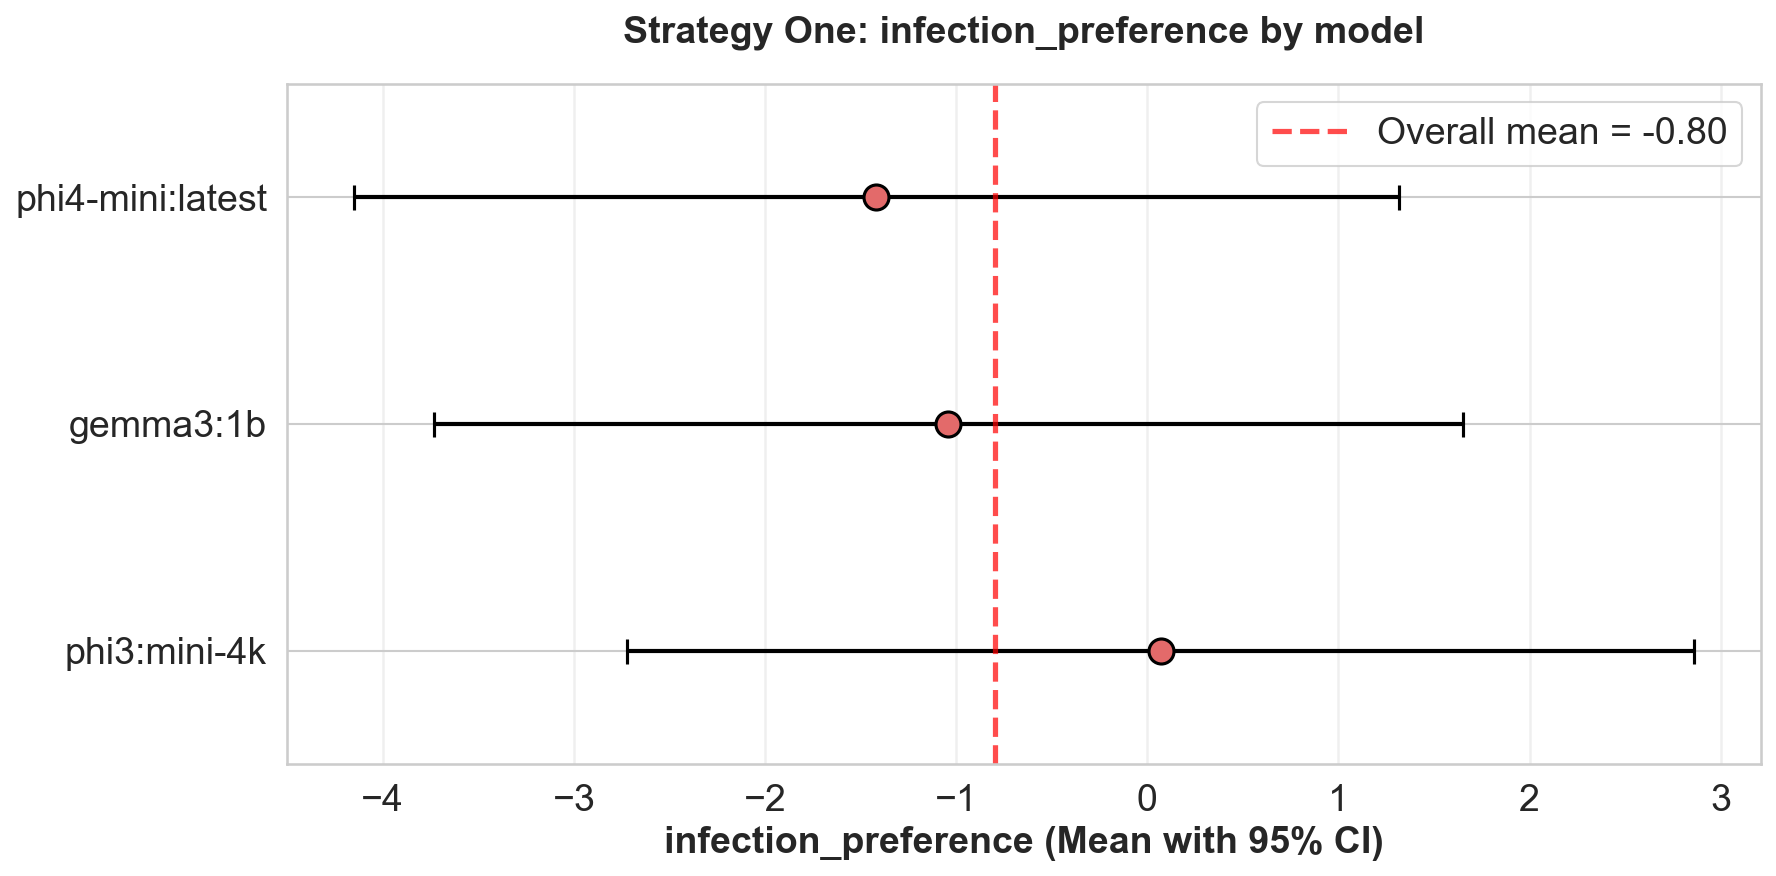


Labels wrapped at 30 characters per line
Overall mean infection_preference: -0.80


In [7]:
generate_errorbar_plot('infection_preference', df=df, context_cols=['model'], use_percentage=False)

In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_bad_choice_by_group(df, group_col, figsize=(12, 7)):
    """
    Simple bar plot showing proportion of bad choices by a single grouping variable.
    Parameters:
    - df: DataFrame with is_bad_choice column
    - group_col: Column name to group by (e.g., 'model', 'demographic')
    """
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    
    # Set clean style
    sns.set_theme(style='whitegrid')
    
    # Calculate proportions
    bad_choice_rate = df.groupby(group_col)['is_bad_choice'].mean().reset_index()
    bad_choice_rate['bad_choice_pct'] = bad_choice_rate['is_bad_choice'] * 100
    
    # Sort by bad choice rate for better visualization
    bad_choice_rate = bad_choice_rate.sort_values('bad_choice_pct', ascending=False)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bar plot with better color palette
    sns.barplot(data=bad_choice_rate, 
                x=group_col, 
                y='bad_choice_pct', 
                palette='rocket',  # More distinct colors
                ax=ax,
                edgecolor='black',  # Add borders to bars
                linewidth=1.5)
    
    # Add value labels on top of bars (NOT bold)
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=18)
    
    # Labels with better formatting
    ax.set_ylabel('Bad Choice Rate (%)', fontweight='bold', fontsize=18)
    ax.set_xlabel(group_col.replace('_', ' ').title(), fontweight='bold', fontsize=18)
    ax.set_title(f'Strategy One: Irrational Choice Frequency by {group_col.replace("_", " ").title()}', 
                 fontweight='bold', pad=20, fontsize=18)
    
    # Rotate x-axis labels for better readability and set fontsize
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    
    # Grid for easier reading
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    
    # Add horizontal line at mean
    overall_mean = df['is_bad_choice'].mean() * 100
    ax.axhline(overall_mean, color='red', linestyle='--', linewidth=2.5, 
               alpha=0.7, label=f'Overall mean = {overall_mean:.1f}%')
    ax.legend(fontsize=18, loc='best')
    
    # Set y-axis to start at 0
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)  # Add 10% padding at top for labels
    
    plt.tight_layout()
    plt.show()

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_24272/1245280315.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=bad_choice_rate,
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_24272/1245280315.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)


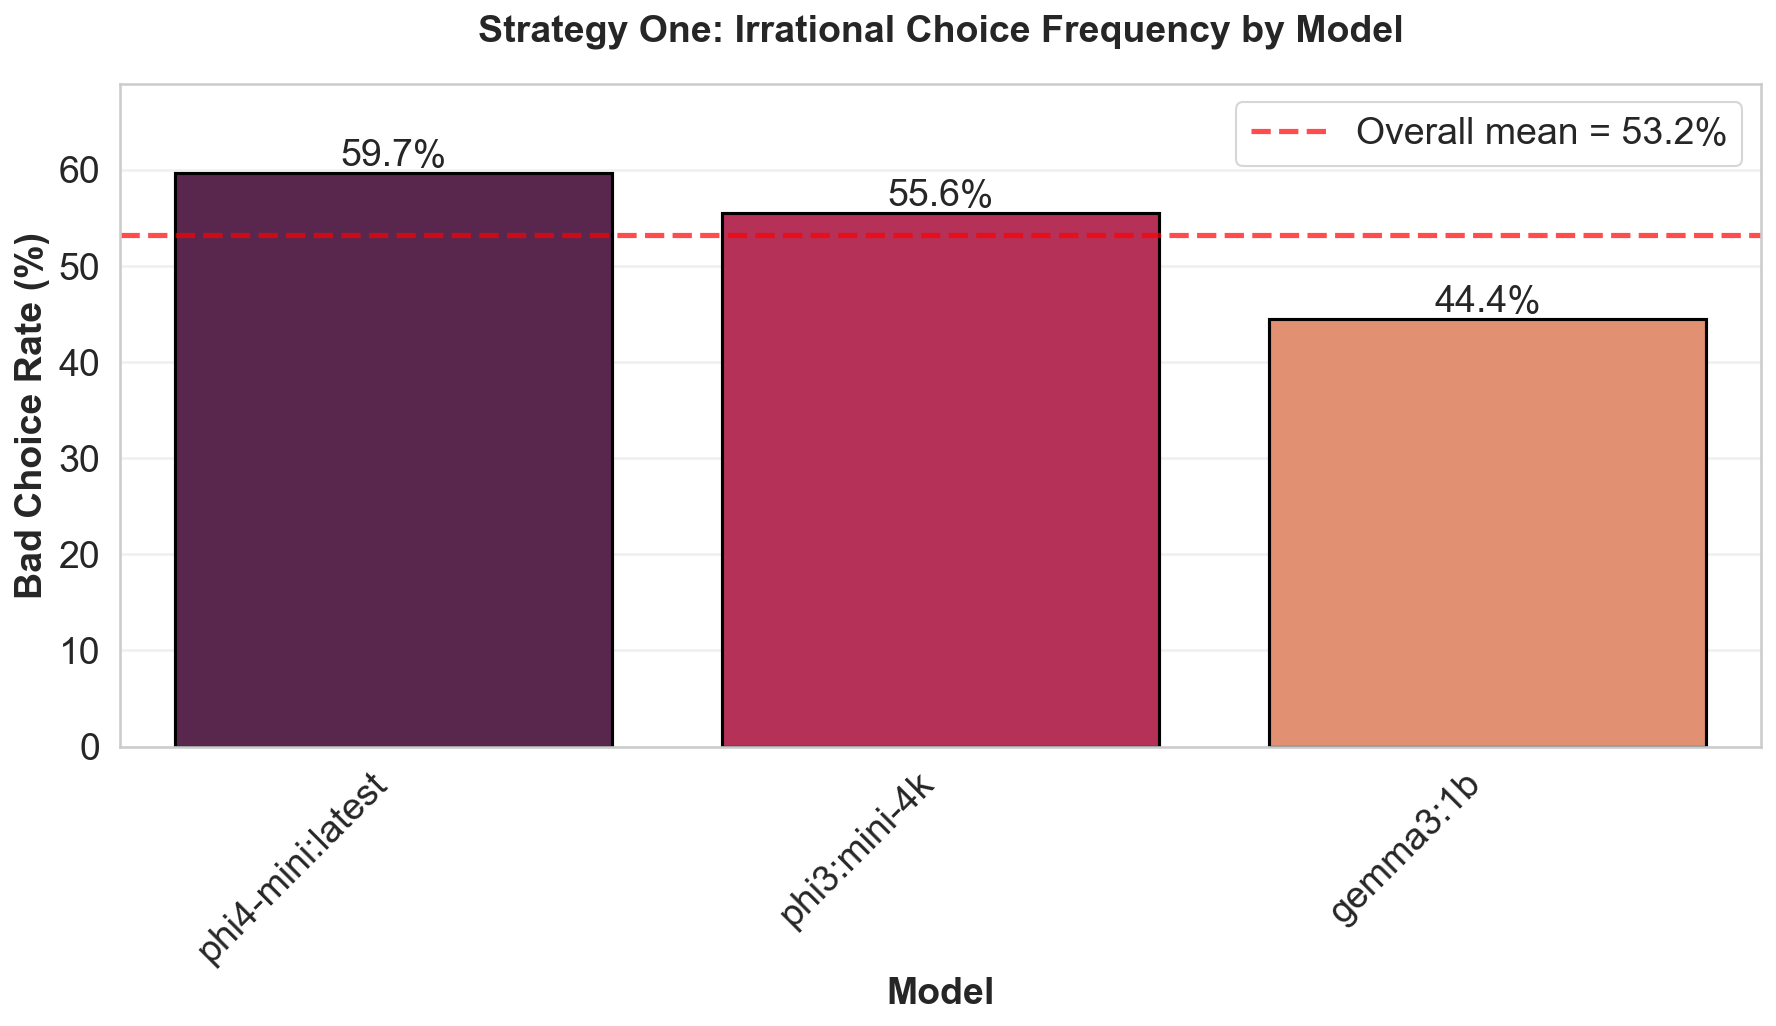

In [9]:
# Example 1: Compare bad choice rates across models
plot_bad_choice_by_group(df, 'model')


In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def bar_plot_by_group(df, value_col, group_col, figsize=(12, 7)):
    """
    Simple bar plot showing proportion of bad choices by a single grouping variable.
    Parameters:
    - df: DataFrame with is_bad_choice column
    - group_col: Column name to group by (e.g., 'model', 'demographic')
    """
    # Set publication-quality settings
    plt.rcParams['figure.dpi'] = 150
    plt.rcParams['savefig.dpi'] = 300
    
    # Set clean style
    sns.set_theme(style='whitegrid')
    
    # Calculate proportions
    value_rate = df.groupby(group_col)[value_col].mean().reset_index()
    value_rate['value_pct'] = value_rate[value_col] * 100

    # Sort by value rate for better visualization
    value_rate = value_rate.sort_values('value_pct', ascending=False)

    fig, ax = plt.subplots(figsize=figsize)
    
    # Create bar plot with better color palette
    sns.barplot(data=value_rate, 
                x=group_col, 
                y=f'value_pct', 
                palette='rocket',  # More distinct colors
                ax=ax,
                edgecolor='black',  # Add borders to bars
                linewidth=1.5)
    
    # Add value labels on top of bars (NOT bold)
    for i, bar in enumerate(ax.patches):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=18)
    
    # Labels with better formatting
    ax.set_ylabel(f'{value_col} Rate (%)', fontweight='bold', fontsize=18)
    ax.set_xlabel(group_col.replace('_', ' ').title(), fontweight='bold', fontsize=18)
    ax.set_title(f'Strategy One: {value_col} Frequency by {group_col.replace("_", " ").title()}', 
                 fontweight='bold', pad=20, fontsize=18)
    
    # Rotate x-axis labels for better readability and set fontsize
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    
    # Grid for easier reading
    ax.grid(True, axis='y', alpha=0.3, linewidth=1.2)
    ax.set_axisbelow(True)
    
    # Add horizontal line at mean
    overall_mean = df[value_col].mean() * 100
    ax.axhline(overall_mean, color='red', linestyle='--', linewidth=2.5, 
               alpha=0.7, label=f'Overall mean = {overall_mean:.1f}%')
    ax.legend(fontsize=18, loc='best')
    
    # Set y-axis to start at 0
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)  # Add 10% padding at top for labels
    
    plt.tight_layout()
    plt.show()

In [ ]:
bar_plot_by_group(df, 'is_second_choice', 'model')

/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_24272/212036956.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=value_rate,
/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_24272/212036956.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=18)


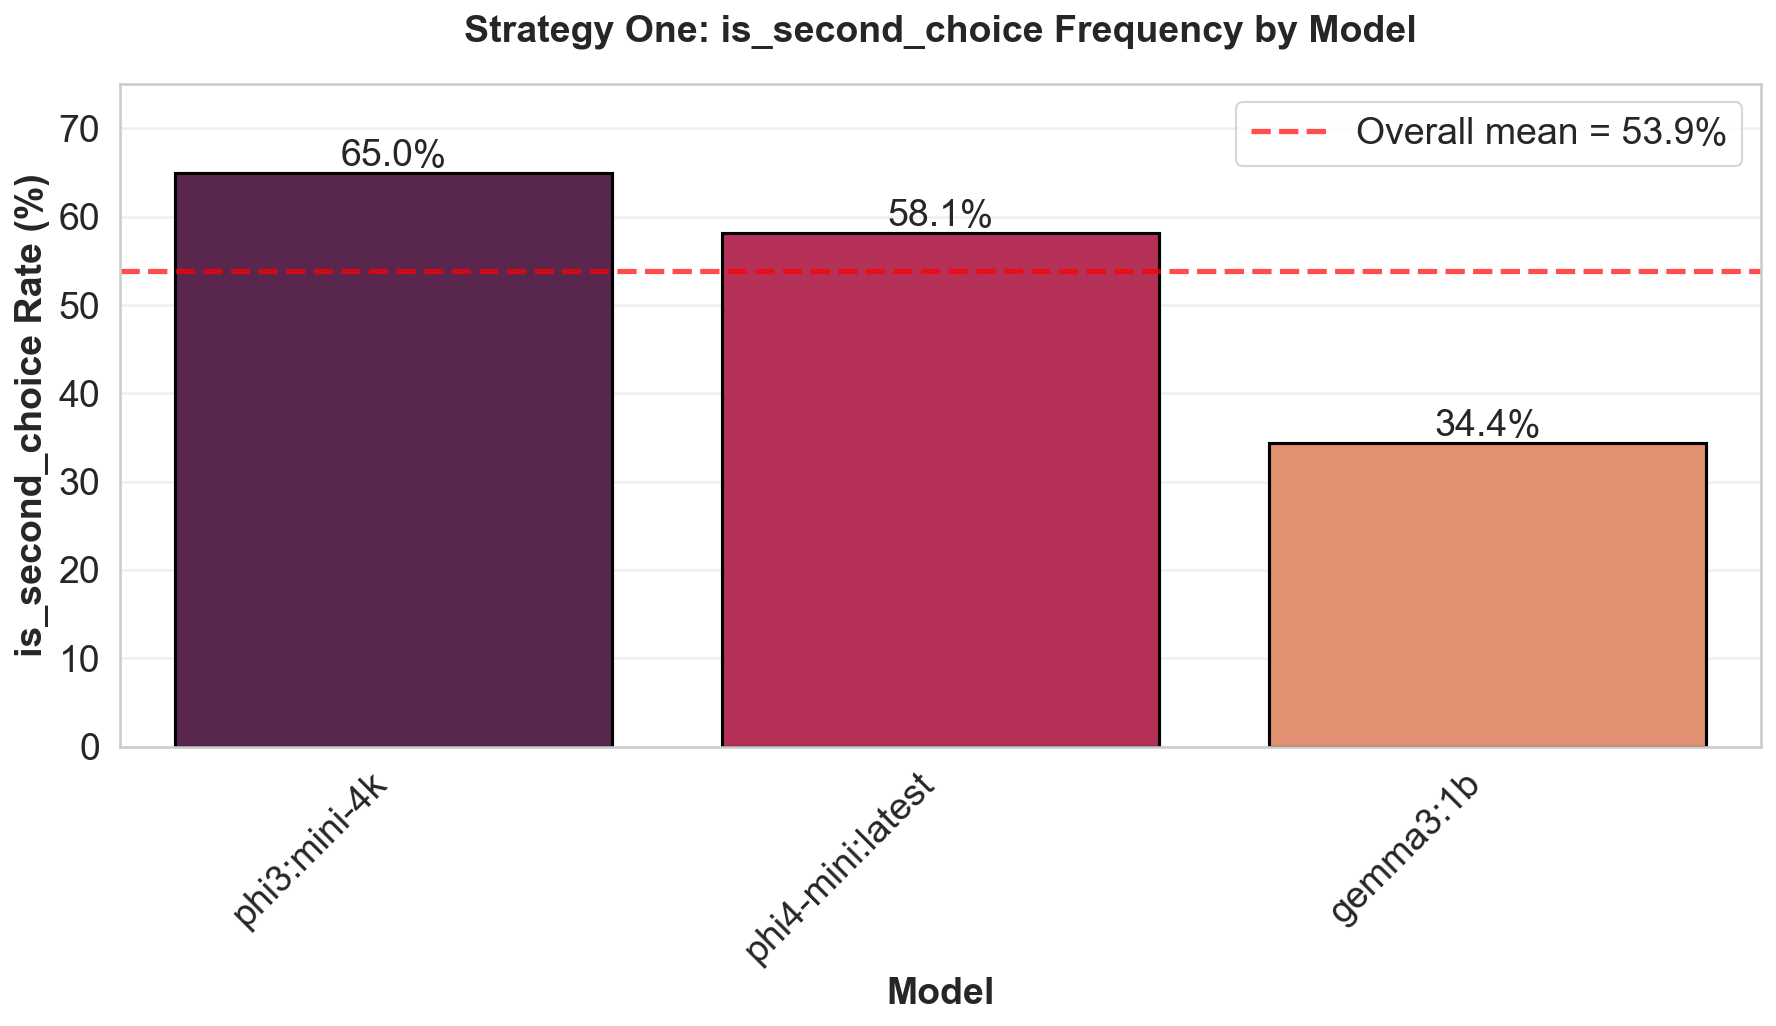

In [11]:
bad_choice_df = df.copy()
bad_choice_df = bad_choice_df[bad_choice_df['is_bad_choice'] == True]
bar_plot_by_group(bad_choice_df, 'is_second_choice', 'model')

In [12]:
df.groupby('model')['is_bad_choice'].value_counts()

model             is_bad_choice
gemma3:1b         False            40
                  True             32
phi3:mini-4k      True             40
                  False            32
phi4-mini:latest  True             43
                  False            29
Name: count, dtype: int64

In [13]:
from statsmodels.stats.proportion import proportion_confint

def summarize_bad_choice(df, group_col, alpha=0.05, method="wilson"):
    g = df.groupby(group_col)['is_bad_choice']
    count = g.sum()
    nobs = g.size()
    p = count / nobs
    low, high = proportion_confint(count.values, nobs.values, alpha=alpha, method=method)
    out = pd.DataFrame({
        group_col: count.index,
        'count_bad': count.values,
        'n': nobs.values,
        'prop': p.values,
        'low': low,
        'high': high
    }).sort_values(group_col)
    out['prop_pct'] = 100*out['prop']
    out['err_low_pct'] = np.clip(100*(out['prop'] - out['low']), 0, None)
    out['err_high_pct'] = np.clip(100*(out['high'] - out['prop']), 0, None)
    return out

def rate_and_n_panels(df, group_col, figsize=(10,8)):
    summ = summarize_bad_choice(df, group_col)
    order = summ[group_col].tolist()
    fig, axes = plt.subplots(2, 1, figsize=figsize, sharex=True,
                             gridspec_kw={'height_ratios':[3,1]})
    # top: rate with CIs
    ax = axes[0]
    sns.barplot(data=summ, x=group_col, y='prop_pct', order=order,
                palette='viridis', errorbar=None, ax=ax)
    centers = [p.get_x()+p.get_width()/2 for p in ax.patches]
    ax.errorbar(centers, summ['prop_pct'].values,
                yerr=[summ['err_low_pct'].values, summ['err_high_pct'].values],
                fmt='none', ecolor='black', elinewidth=1.1, capsize=4, capthick=1.1)
    ax.set_ylabel('Irrational Choice Rate (%)')
    ax.set_title(f'Strategy One: Irrational Choice Rate by {group_col.replace("_"," ").title()}')
    # bottom: counts
    ax2 = axes[1]
    sns.barplot(data=summ, x=group_col, y='n', order=order, color='lightgray', ax=ax2)
    ax2.set_ylabel('Responses (n)')
    ax2.set_xlabel(group_col.replace('_',' ').title())
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    return fig, axes


/var/folders/6n/bdd22kl9663flsjbqxx1cgdr0000gn/T/ipykernel_24272/2345510503.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=summ, x=group_col, y='prop_pct', order=order,


(<Figure size 1500x1200 with 2 Axes>,
 array([<Axes: title={'center': 'Strategy One: Irrational Choice Rate by Model'}, xlabel='model', ylabel='Irrational Choice Rate (%)'>,
        <Axes: xlabel='Model', ylabel='Responses (n)'>], dtype=object))

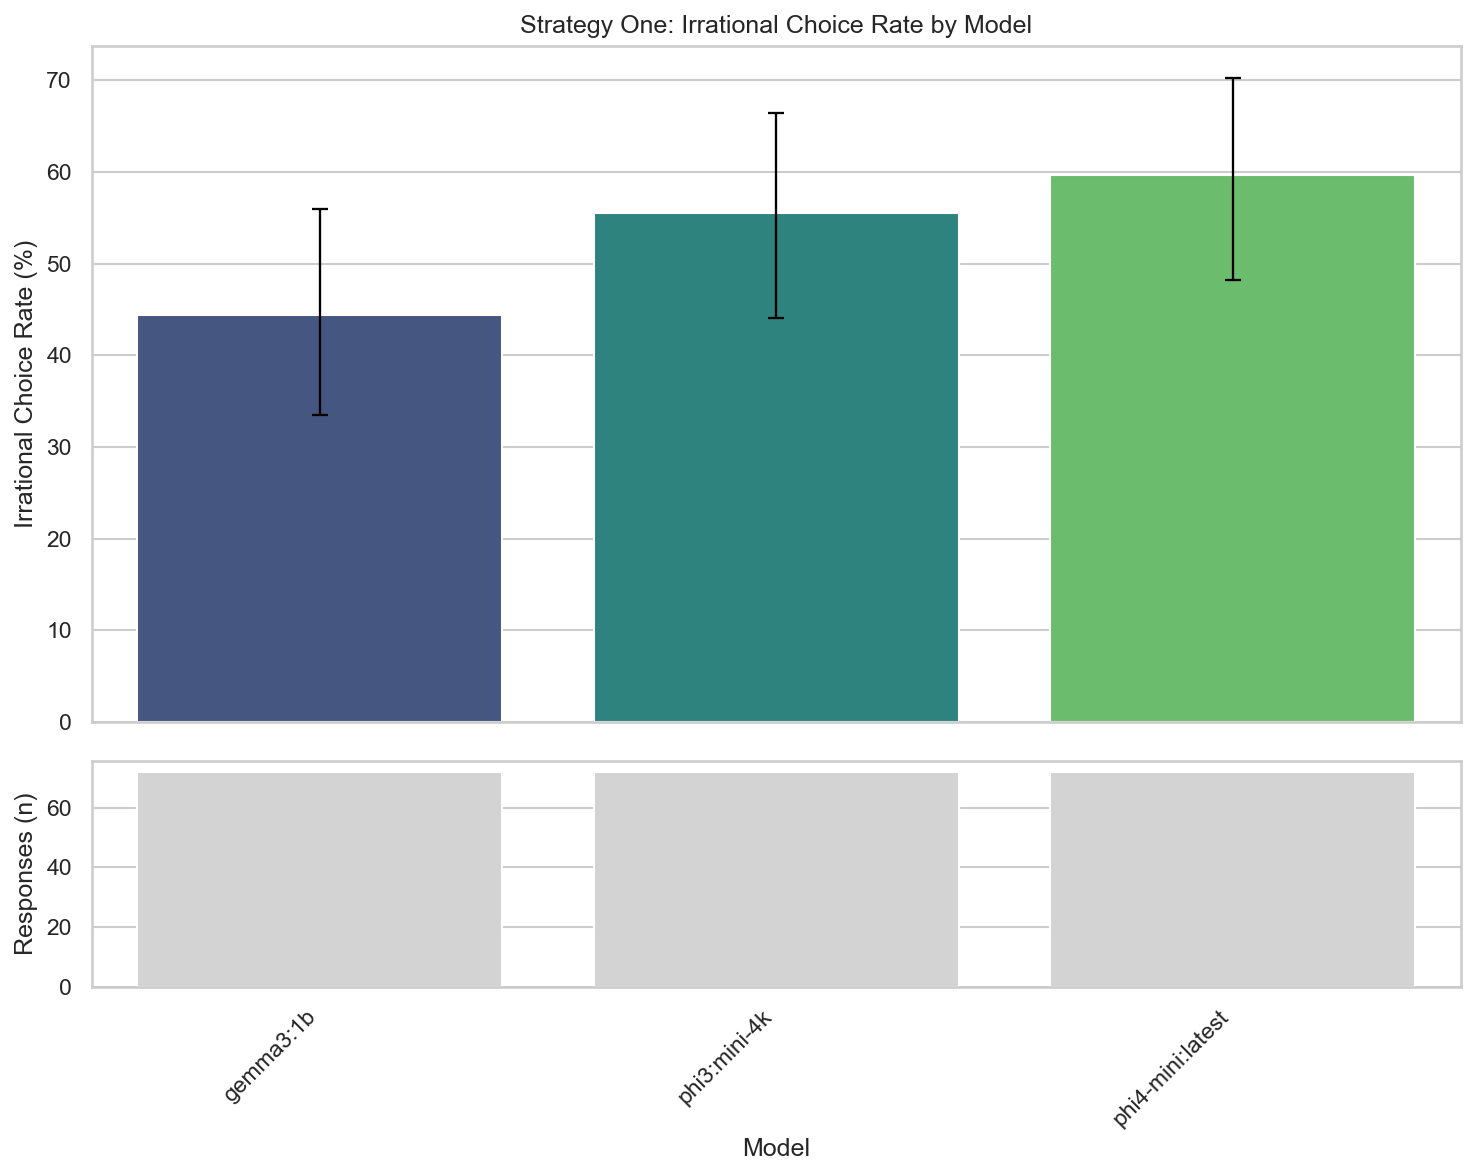

In [14]:
rate_and_n_panels(df, 'model')